# 🏨 Analisis Booking & Pendapatan Hotel (Jan–Jun 2026)
**Oleh:** Ihsan Amiruddin · **Tools:** Python, Pandas, Matplotlib, Seaborn

> Studi kasus portofolio dengan **dataset simulasi**.

## Skenario
Manajemen sebuah hotel ingin tahu tipe kamar dan channel mana yang paling menguntungkan, serta seberapa besar kerugian akibat pembatalan. Pertanyaan yang dijawab:
1. Berapa pendapatan yang hilang akibat pembatalan dan dari channel mana?
2. Kombinasi tipe kamar × channel mana yang paling untung dan paling berisiko?
3. Apakah tamu yang menginap lebih lama lebih bernilai?
4. Kapan tamu paling banyak check-in dan apakah harga akhir pekan sudah optimal?

## 1. Load Data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
rp = lambda x: f"Rp {x:,.0f}".replace(",", ".")


In [2]:
# Di Google Colab: upload file CSV ke panel kiri, lalu sesuaikan PATH bila perlu
import os
PATH = "data/hotel_booking_revenue_analysis_raw.csv" if os.path.exists("data/hotel_booking_revenue_analysis_raw.csv") else "hotel_booking_revenue_analysis_raw.csv"
df_raw = pd.read_csv(PATH)
df_raw.head()

,booking_id,check_in,check_out,room_type,guests,nights,booking_channel,payment_method,customer_type,booking_status,nightly_rate,revenue
0,HTL00017,2026-01-01,2026-01-06,Deluxe,1,5,Website,QRIS,New Guest,Completed,500000,2500000
1,HTL00221,2026-01-01,2026-01-02,Superior,3,1,Online Travel Agent,Bank Transfer,Returning Guest,Completed,680000,680000
2,HTL00299,2026-01-01,2026-01-03,Deluxe,2,2,Website,Credit Card,Returning Guest,Completed,500000,1000000
3,HTL00469,2026-01-01,2026-01-04,Deluxe,2,3,Website,Debit Card,New Guest,Completed,500000,1500000
4,HTL00499,2026-01-01,2026-01-05,Family,2,4,Website,QRIS,Returning Guest,Completed,800000,3200000


## 2. Data Understanding

In [3]:
print("Ukuran:", df_raw.shape)
df_raw.info()
print("\nMissing value:"); print(df_raw.isna().sum()[lambda s: s > 0])
print("\nBaris dobel:", df_raw.duplicated().sum())

Ukuran: (3520, 12)
<class 'pandas.DataFrame'>
RangeIndex: 3520 entries, 0 to 3519
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   booking_id       3520 non-null   str  
 1   check_in         3520 non-null   str  
 2   check_out        3520 non-null   str  
 3   room_type        3520 non-null   str  
 4   guests           3520 non-null   int64
 5   nights           3520 non-null   int64
 6   booking_channel  3511 non-null   str  
 7   payment_method   3512 non-null   str  
 8   customer_type    3512 non-null   str  
 9   booking_status   3520 non-null   str  
 10  nightly_rate     3520 non-null   int64
 11  revenue          3520 non-null   int64
dtypes: int64(4), str(8)
memory usage: 593.1 KB

Missing value:
booking_channel    9
payment_method     8
customer_type      8
dtype: int64

Baris dobel: 20


**Temuan kualitas data:** 20 booking dobel (dihapus) dan data kosong di `booking_channel`, `payment_method`, `customer_type` (diisi `Unknown`).

## 3. Data Cleaning

In [4]:
df = df_raw.drop_duplicates(subset="booking_id").copy()
for c in ["booking_channel", "payment_method", "customer_type"]:
    df[c] = df[c].fillna("Unknown")
df["check_in"] = pd.to_datetime(df["check_in"]); df["check_out"] = pd.to_datetime(df["check_out"])
df["month"] = df["check_in"].dt.to_period("M").astype(str)
df["day_name"] = df["check_in"].dt.day_name()
df["cancelled"] = df.booking_status.eq("Cancelled")
df["potential_loss"] = df.nights * df.nightly_rate * df.cancelled

# Validasi konsistensi
print("Malam tidak cocok tanggal   :", ((df.check_out - df.check_in).dt.days != df.nights).sum())
print("Revenue tidak cocok (selesai):", ((df.nights * df.nightly_rate != df.revenue) & ~df.cancelled).sum())
print("Booking batal tapi ada revenue:", (df.cancelled & (df.revenue > 0)).sum())
ok = df[~df.cancelled]
print("Data bersih:", df.shape)
os.makedirs("data", exist_ok=True); df.to_csv("data/hotel_booking_clean.csv", index=False)

Malam tidak cocok tanggal   : 0
Revenue tidak cocok (selesai): 0
Booking batal tapi ada revenue: 0
Data bersih: (3500, 16)


## 4. KPI

In [5]:
print("Pendapatan (booking selesai):", rp(ok.revenue.sum()))
print("Total booking               :", f"{len(df):,}")
print("Tingkat pembatalan          :", f"{df.cancelled.mean()*100:.1f}%")
print("Potensi pendapatan hilang   :", rp(df.potential_loss.sum()))

Pendapatan (booking selesai): Rp 4.851.790.000
Total booking               : 3,500
Tingkat pembatalan          : 9.8%
Potensi pendapatan hilang   : Rp 524.735.000


## 5. Pendapatan Bulanan & Hari Check-in

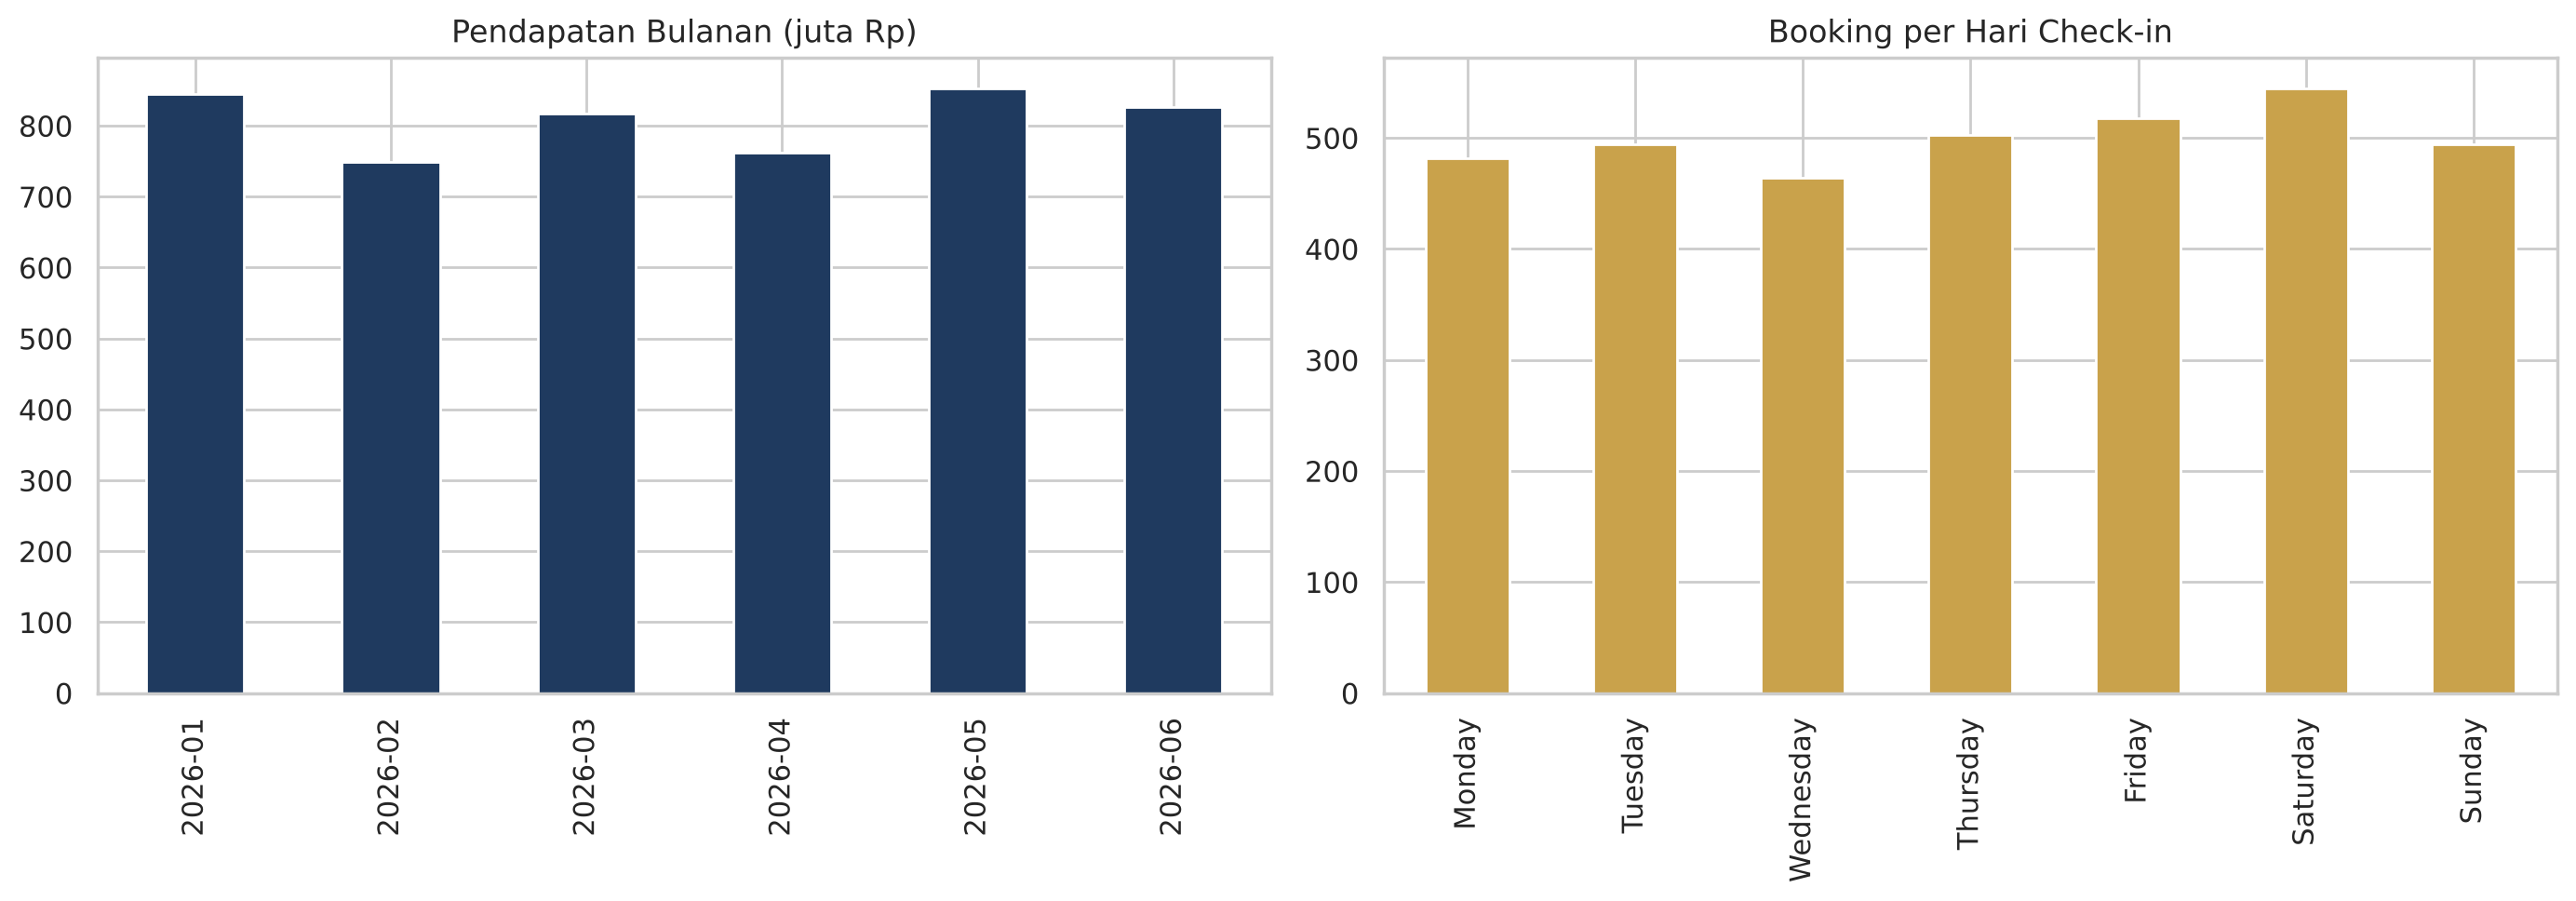

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
(ok.groupby("month").revenue.sum() / 1e6).plot(kind="bar", ax=ax[0], color="#1F3A5F"); ax[0].set_title("Pendapatan Bulanan (juta Rp)"); ax[0].set_xlabel("")
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
df.groupby("day_name").size().reindex(order).plot(kind="bar", ax=ax[1], color="#C9A24B"); ax[1].set_title("Booking per Hari Check-in"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

**Insight:** Pendapatan tertinggi di Mei (±Rp853 juta) dan terendah di Februari (±Rp749 juta). Check-in terbanyak jatuh di Sabtu (545 booking), terendah di Rabu (464).

## 6. Tipe Kamar

           pendapatan  booking      tarif
room_type                                
Deluxe     1193875000      871   515235.0
Superior   1063455000      631   669017.0
Standard    897095000      973   361989.0
Family      884600000      426   827160.0
Suite       812765000      255  1240961.0


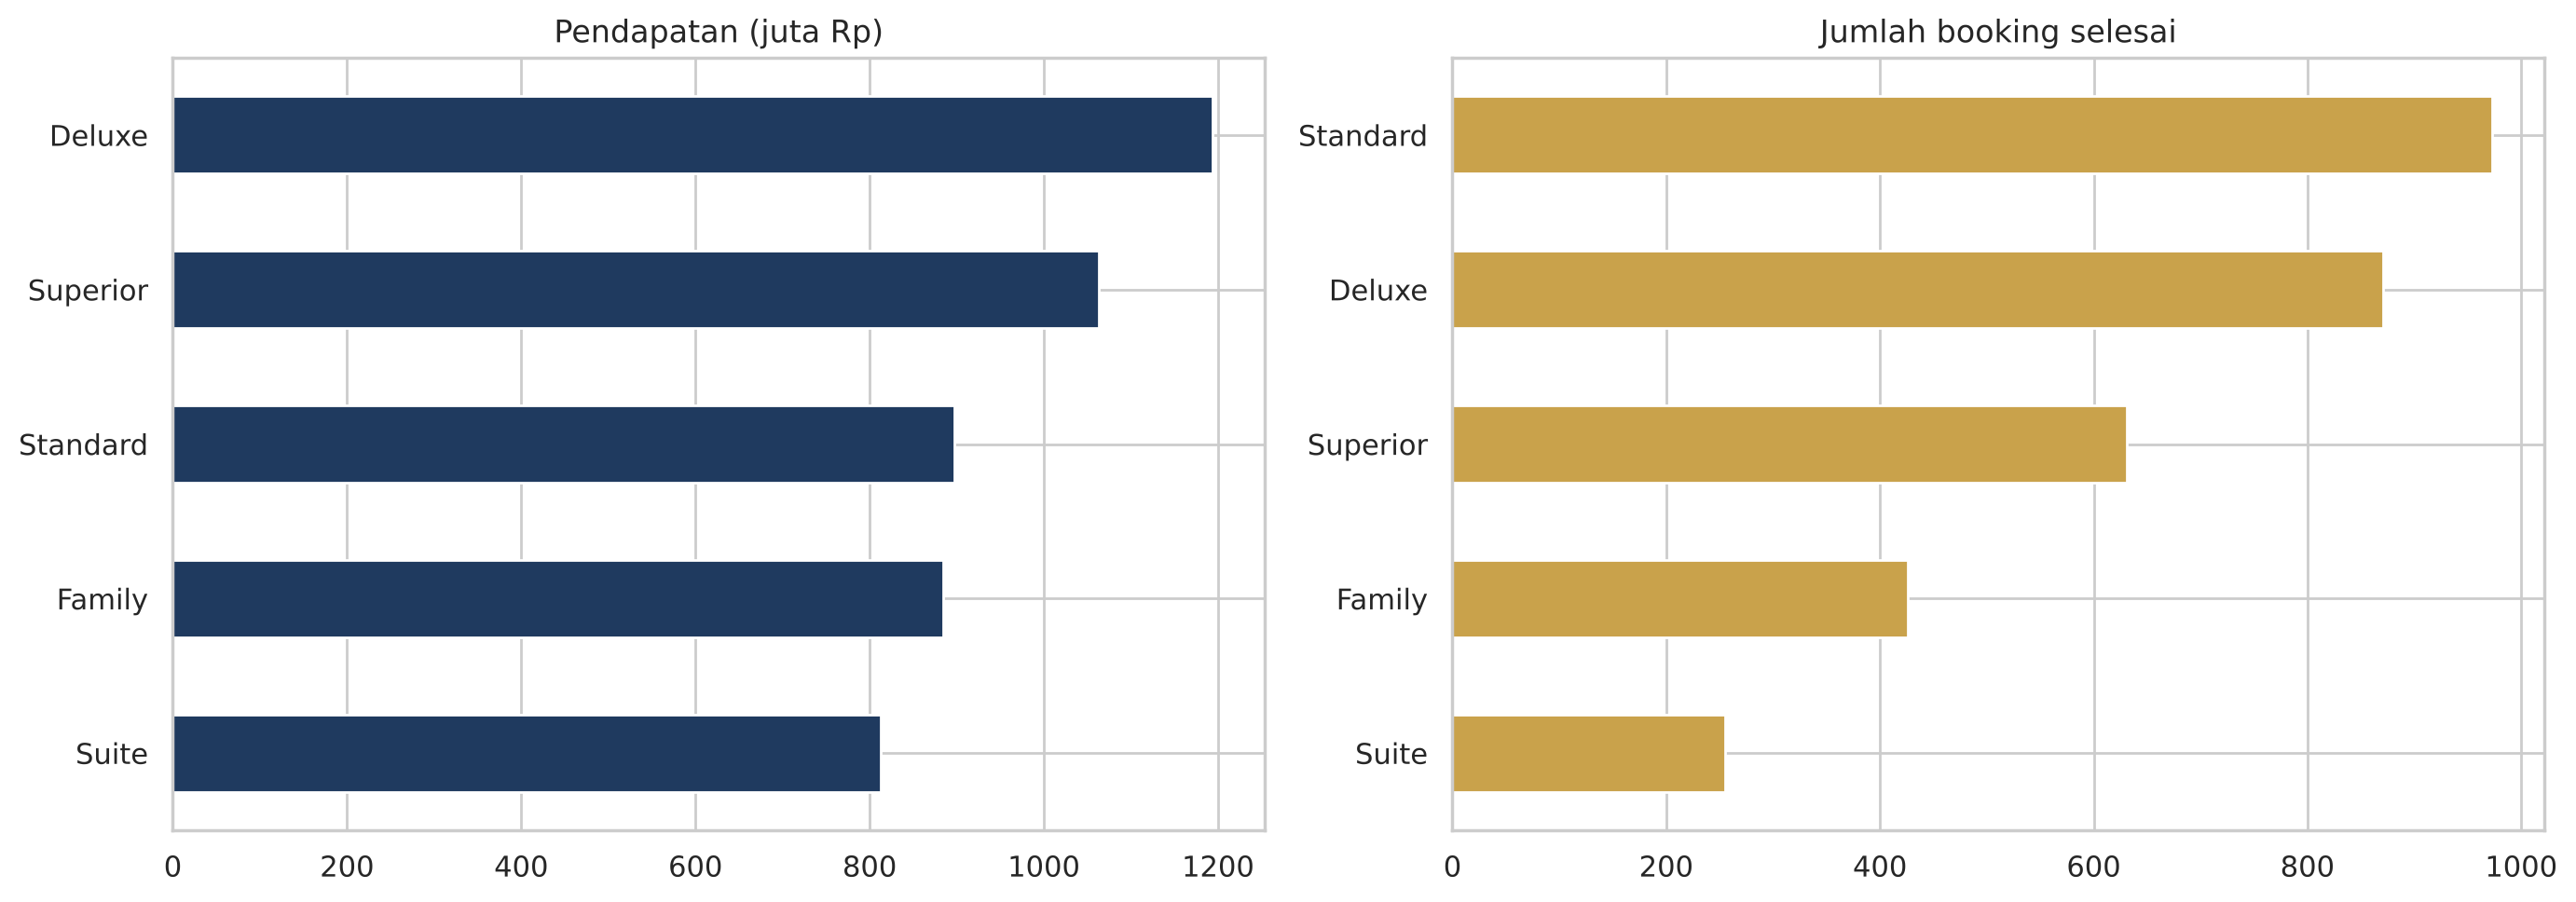

In [7]:
room = ok.groupby("room_type").agg(pendapatan=("revenue","sum"), booking=("revenue","size"), tarif=("nightly_rate","mean")).round(0)
print(room.sort_values("pendapatan", ascending=False))
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
(room.pendapatan.sort_values() / 1e6).plot(kind="barh", ax=ax[0], color="#1F3A5F"); ax[0].set_title("Pendapatan (juta Rp)"); ax[0].set_ylabel("")
room.booking.sort_values().plot(kind="barh", ax=ax[1], color="#C9A24B"); ax[1].set_title("Jumlah booking selesai"); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()

**Insight:** *Deluxe* menyumbang pendapatan terbesar (±Rp1,19 miliar). *Standard* paling banyak dipesan (973) tetapi tarifnya rendah (±Rp362 ribu), sedangkan *Suite* hanya 255 booking namun tarifnya tertinggi (±Rp1,24 juta) dan tetap menyumbang ±Rp813 juta.

## 7. Channel & Pembatalan

                     booking  batal_pct  pendapatan_juta
booking_channel                                         
Corporate                496        6.0            650.0
Online Travel Agent     1456       13.7           2006.0
Unknown                    9       11.1             12.0
Walk-in                  665        7.8            954.0
Website                  874        7.1           1230.0


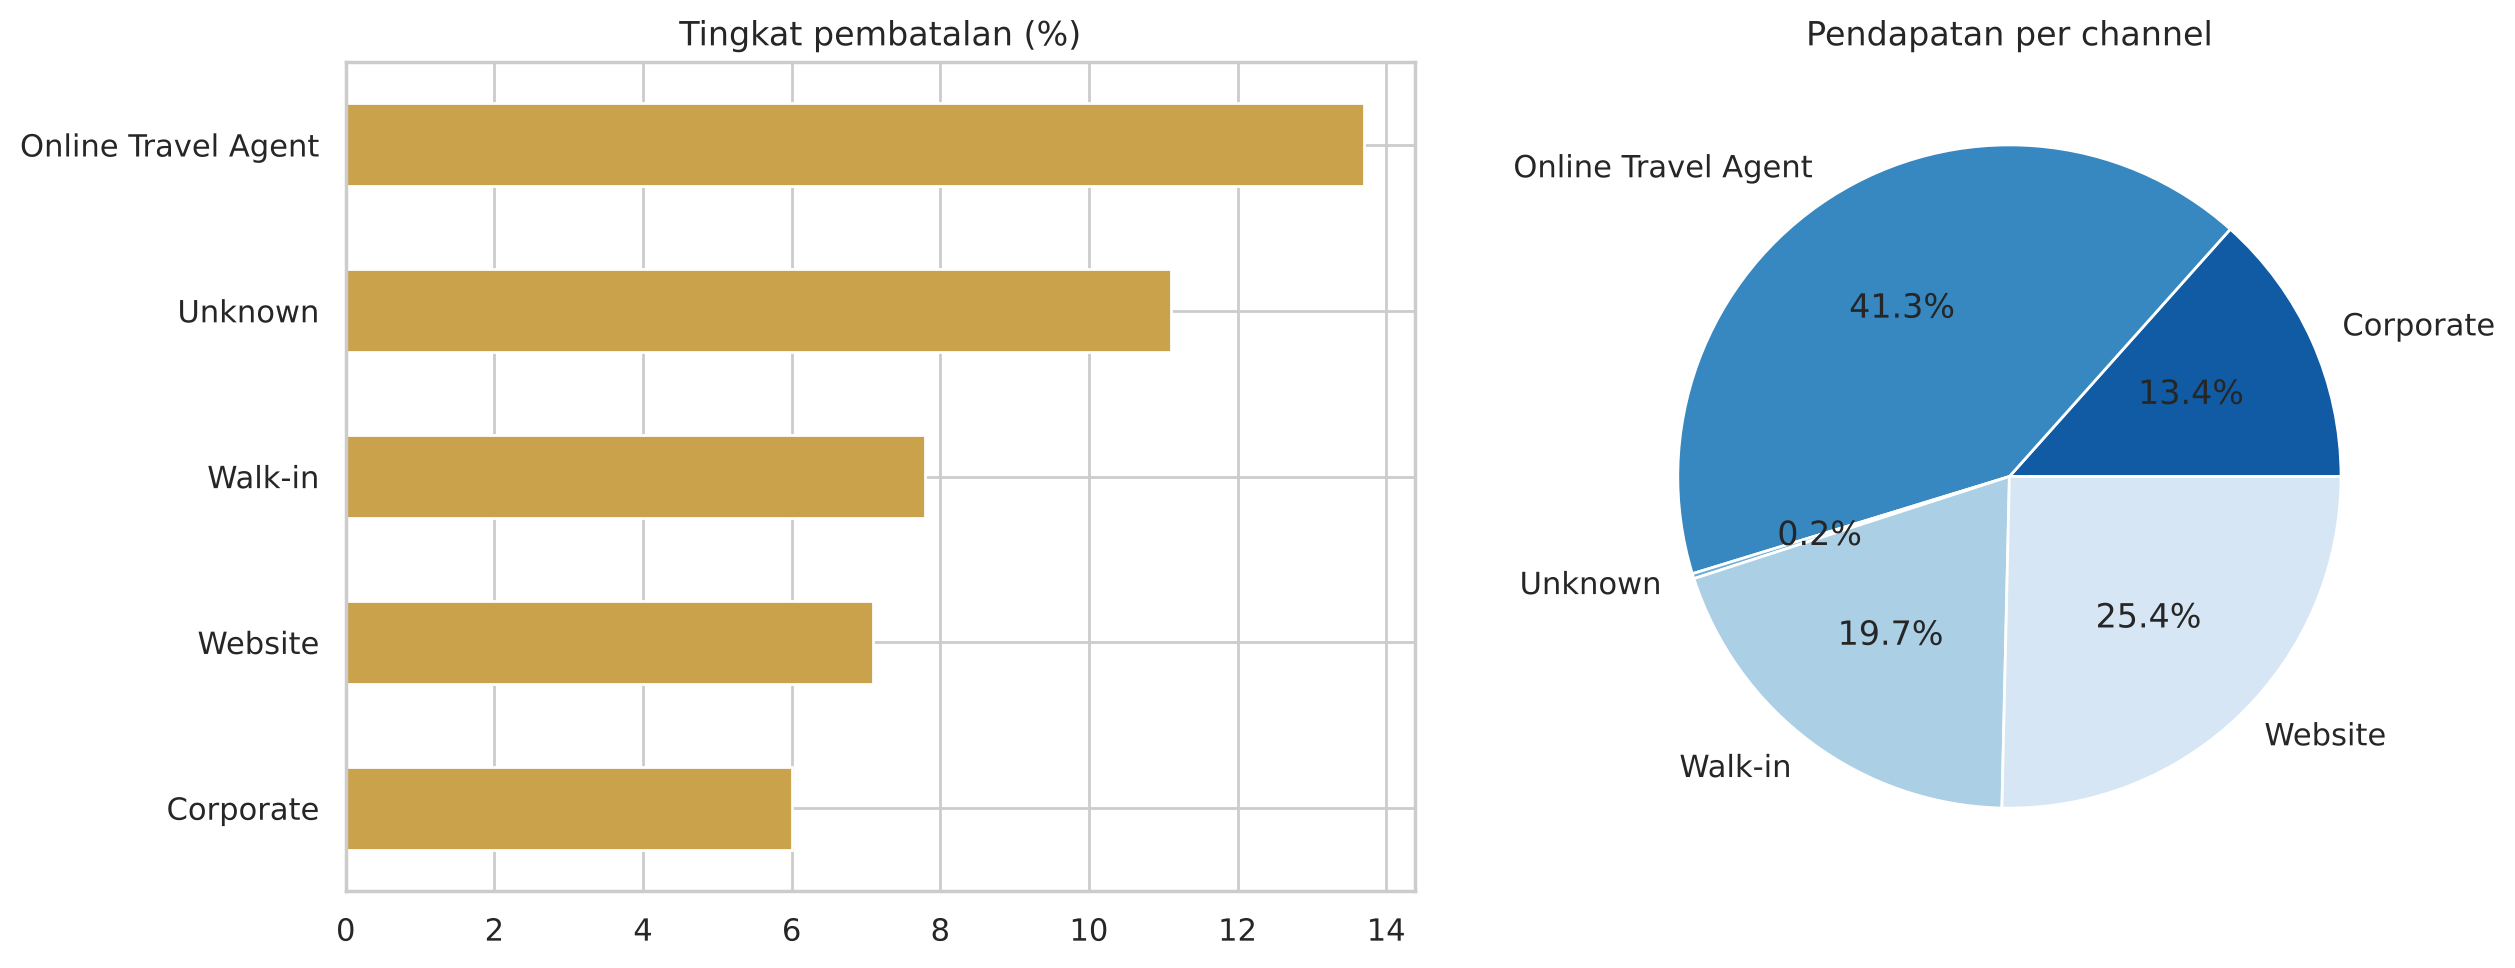

In [8]:
ch = df.groupby("booking_channel").agg(booking=("booking_id","size"), batal_pct=("cancelled", lambda s: s.mean()*100)).round(1)
rev = ok.groupby("booking_channel").revenue.sum()
ch["pendapatan_juta"] = (rev / 1e6).round(0); print(ch)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ch.batal_pct.sort_values().plot(kind="barh", ax=ax[0], color="#C9A24B"); ax[0].set_title("Tingkat pembatalan (%)"); ax[0].set_ylabel("")
(rev / 1e6).plot(kind="pie", autopct="%1.1f%%", ax=ax[1], colors=sns.color_palette("Blues_r", 5)); ax[1].set_ylabel(""); ax[1].set_title("Pendapatan per channel")
plt.tight_layout(); plt.show()

**Insight:** *Online Travel Agent* menyumbang ±41% pendapatan, tetapi tingkat pembatalannya tertinggi (±13,7%), lebih dari dua kali lipat *Corporate* (±6,0%). Pembatalan seluruhnya ±9,8% dengan potensi pendapatan hilang ±Rp525 juta.

## 8. Pembatalan per Bulan & Profil Tamu

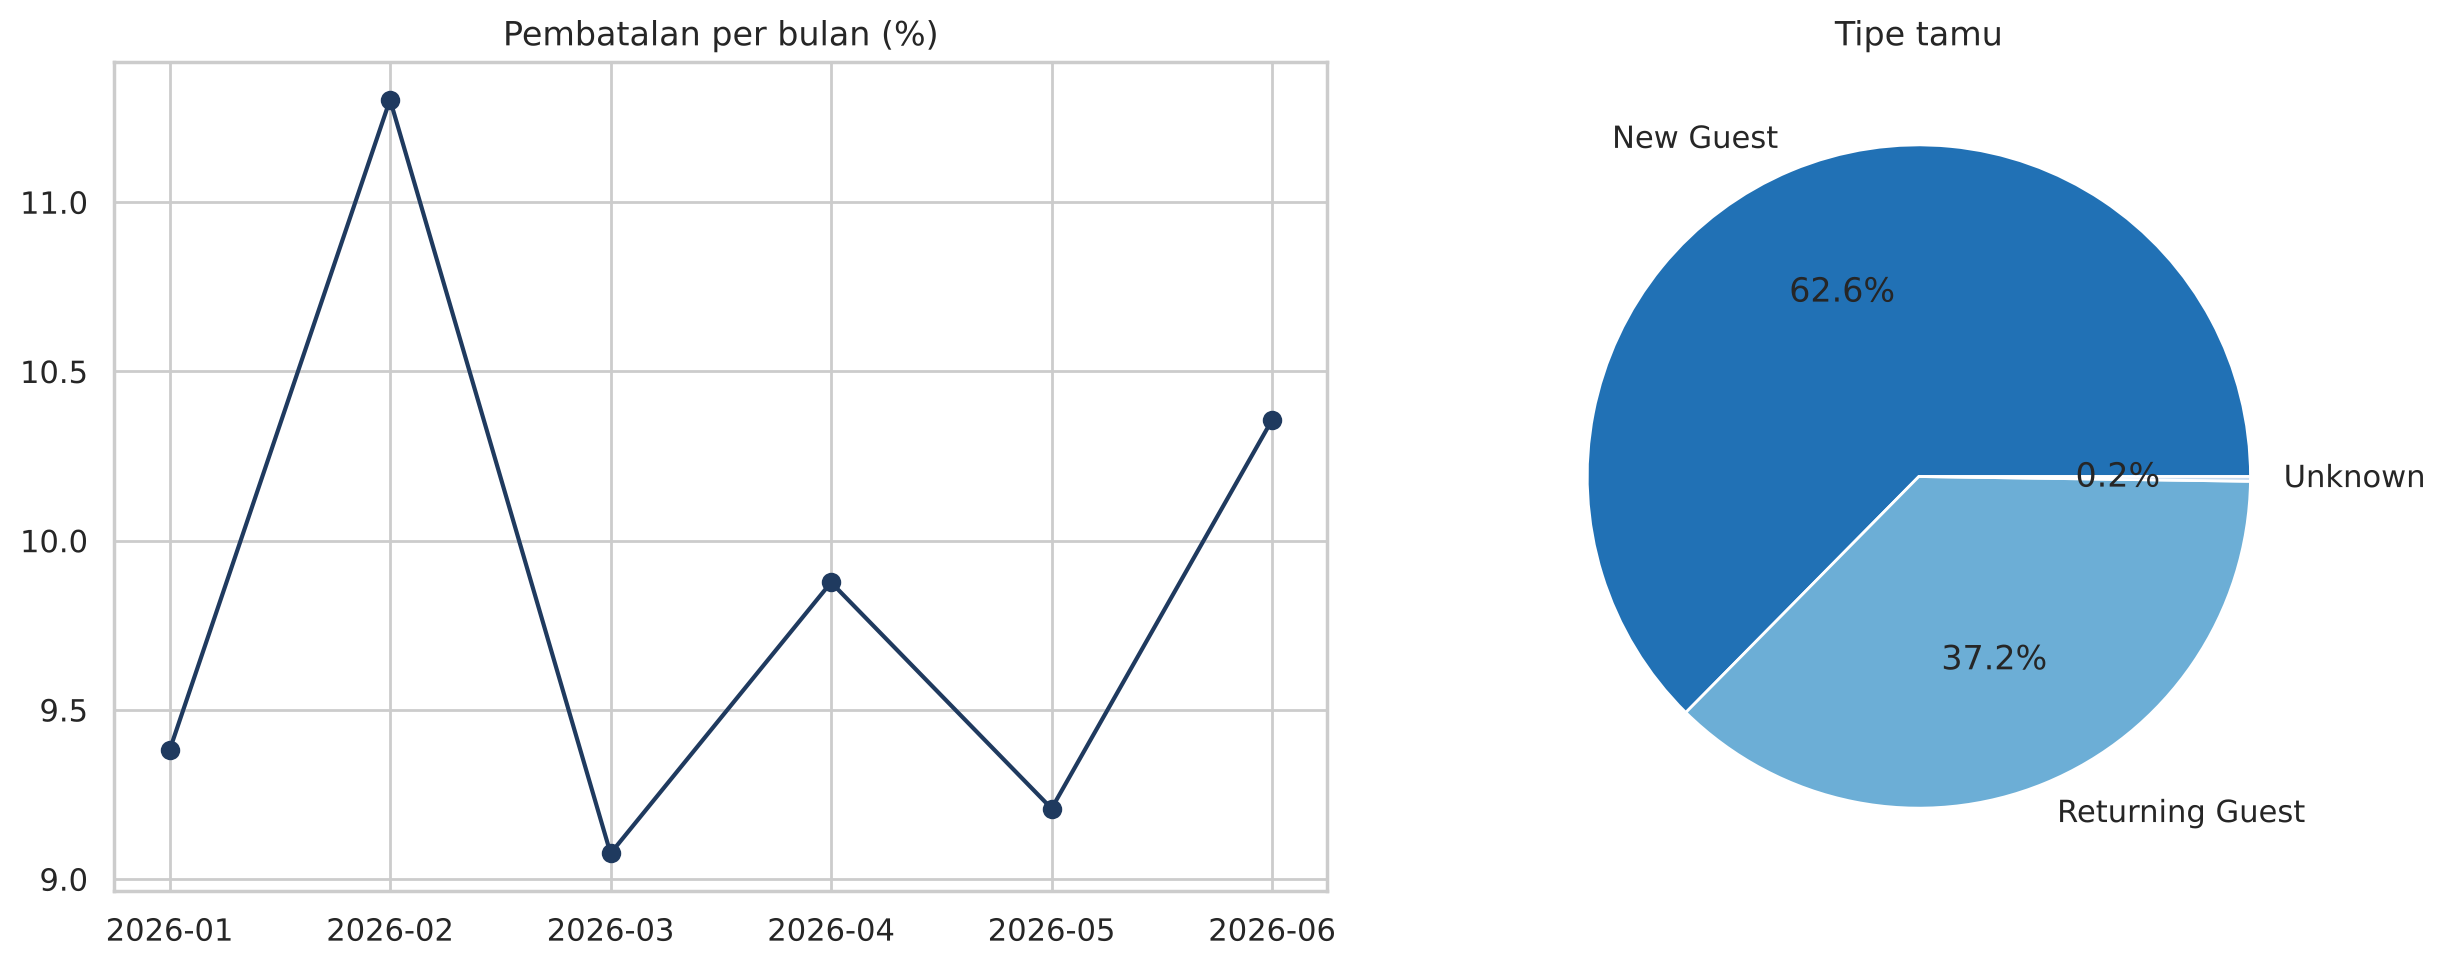

room_type
Deluxe       8.5
Family       9.9
Standard    10.2
Suite        8.6
Superior    11.5
Name: cancelled, dtype: float64


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
(df.groupby("month").cancelled.mean() * 100).plot(marker="o", ax=ax[0], color="#1F3A5F"); ax[0].set_title("Pembatalan per bulan (%)"); ax[0].set_xlabel("")
df.customer_type.value_counts().plot(kind="pie", autopct="%1.1f%%", ax=ax[1], colors=sns.color_palette("Blues_r", 3)); ax[1].set_ylabel(""); ax[1].set_title("Tipe tamu")
plt.tight_layout(); plt.show()
print(df.groupby("room_type").cancelled.mean().mul(100).round(1))

**Insight:** Pembatalan berkisar 9–11% per bulan, tertinggi di Februari (±11,3%). Tamu baru sekitar 63% dari booking dan tamu kembali ±37%, dengan nilai belanja per booking hampir sama.

## Analisis Lanjutan (dipakai di dashboard)

Pendapatan (juta Rp): kamar x channel
booking_channel  Corporate  Online Travel Agent  Walk-in  Website
room_type                                                        
Deluxe               159.0                481.0    236.0    315.0
Family               107.0                331.0    198.0    244.0
Standard             122.0                370.0    181.0    219.0
Suite                111.0                371.0    141.0    190.0
Superior             151.0                453.0    198.0    262.0

Pembatalan (%): kamar x channel
booking_channel  Corporate  Online Travel Agent  Walk-in  Website
room_type                                                        
Deluxe                 4.5                 12.3      9.0      4.7
Family                 3.8                 13.6      8.2      8.5
Standard               5.7                 14.1      6.9      8.7
Suite                  2.4                 12.7     11.3      1.7
Superior              11.0                 15.2      5.6      8.8


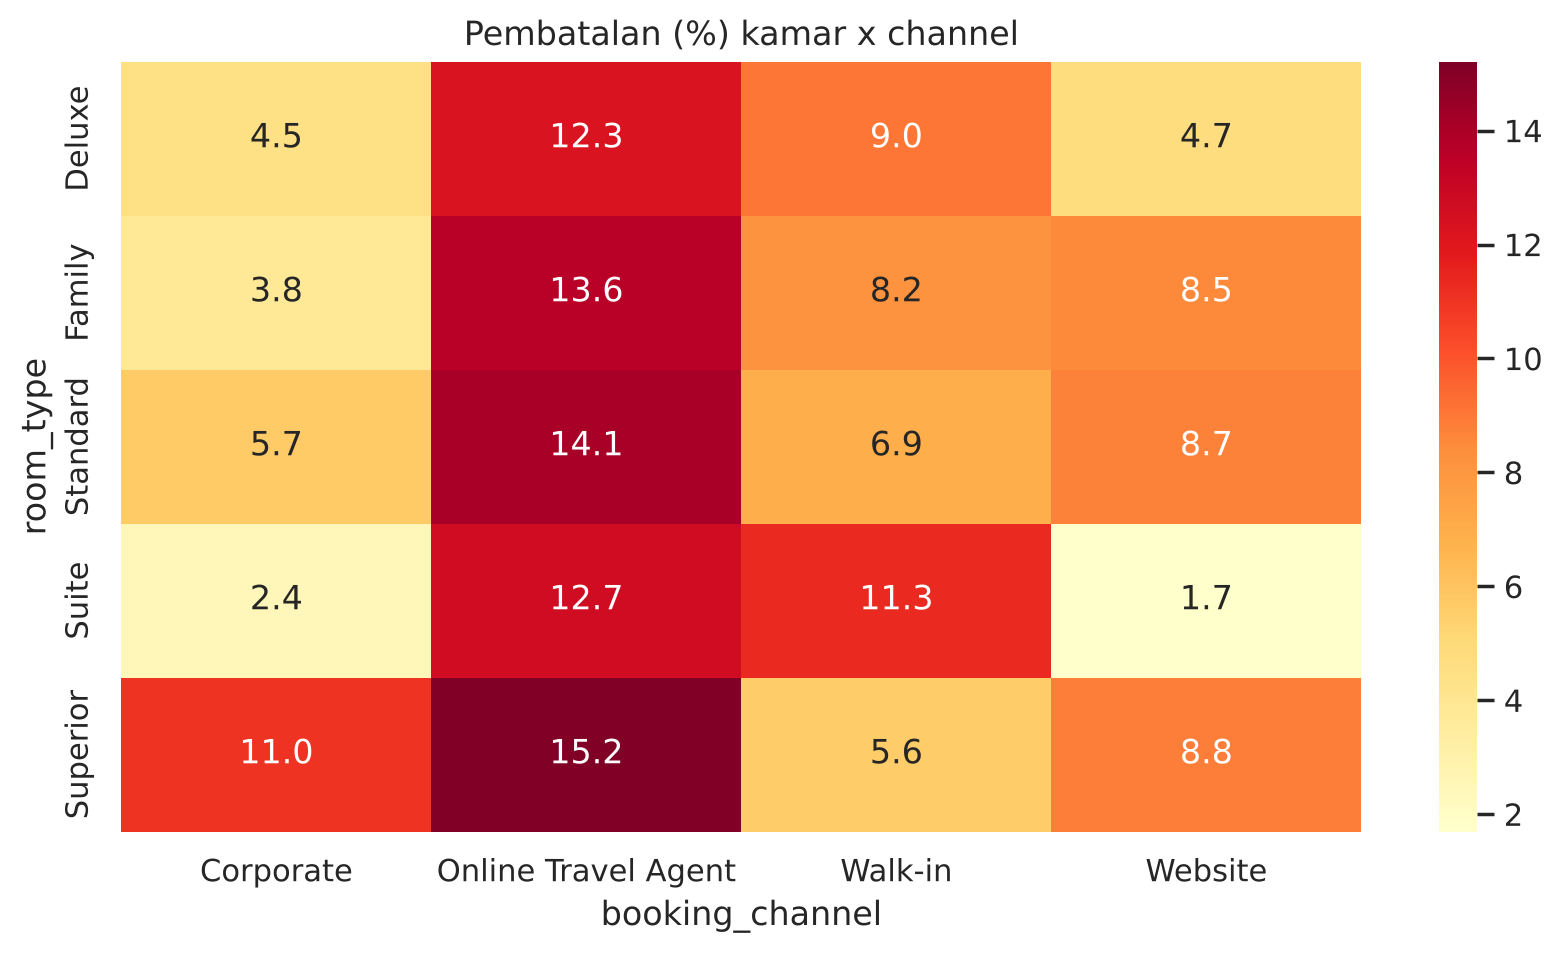

In [10]:
g = df[(df.booking_channel != "Unknown")]
print("Pendapatan (juta Rp): kamar x channel"); print((g[~g.cancelled].pivot_table(index="room_type", columns="booking_channel", values="revenue", aggfunc="sum") / 1e6).round(0))
print("\nPembatalan (%): kamar x channel"); print((g.pivot_table(index="room_type", columns="booking_channel", values="cancelled", aggfunc="mean") * 100).round(1))
sns.heatmap(g.pivot_table(index="room_type", columns="booking_channel", values="cancelled", aggfunc="mean") * 100, annot=True, fmt=".1f", cmap="YlOrRd"); plt.title("Pembatalan (%) kamar x channel"); plt.show()

**Insight:** OTA unggul di semua tipe kamar. *Suite* via Website hampir tidak pernah dibatalkan (±1,7%), sedangkan *Suite* via OTA ±12,7%. Metode pembayaran tidak membedakan pembatalan (±9–10% di semua metode).

In [11]:
n = df.groupby("nights").agg(booking=("booking_id","size"), batal=("cancelled","mean")); n["rev_per_booking_juta"] = (ok.groupby("nights").revenue.mean() / 1e6).round(2); print(n.round(3))
long_ = ok[ok.nights >= 5]
print("\n>=5 malam: % booking", round(len(long_)/len(ok)*100, 1), "| % pendapatan", round(long_.revenue.sum()/ok.revenue.sum()*100, 1))
wk = ok.assign(grp=ok.check_in.dt.dayofweek.isin([4,5]).map({True:"Jumat-Sabtu", False:"Hari lain"})).groupby("grp").nightly_rate.mean().round(0); print("\nTarif rata-rata / malam:\n", wk)

        booking  batal  rev_per_booking_juta
nights                                      
1           963  0.091                  0.61
2          1088  0.101                  1.18
3           666  0.108                  1.79
4           342  0.094                  2.41
5           227  0.110                  2.93
6           146  0.075                  3.49
7            68  0.088                  4.64

>=5 malam: % booking 12.6 | % pendapatan 27.8

Tarif rata-rata / malam:
 grp
Hari lain      592138.0
Jumat-Sabtu    616443.0
Name: nightly_rate, dtype: float64


**Insight:** Menginap 5 malam atau lebih hanya ±12,6% dari booking tetapi menyumbang ±27,8% pendapatan (pendapatan per booking naik dari ±Rp0,6 juta di 1 malam menjadi ±Rp4,6 juta di 7 malam). Tarif Jumat–Sabtu hanya ±4% lebih tinggi dari hari lain (±Rp616 ribu vs ±Rp592 ribu), sehingga harga akhir pekan masih bisa dioptimalkan.

## 9. Kesimpulan & Rekomendasi
| Temuan | Rekomendasi |
|---|---|
| OTA kontribusi terbesar tetapi pembatalan tertinggi | Terapkan kebijakan deposit atau pembatalan berbayar khusus OTA |
| Corporate pembatalan terendah (±6%) | Perluas kerja sama korporat untuk pendapatan lebih stabil |
| Deluxe pendapatan tertinggi; Suite tarif tertinggi | Dorong upselling dari Standard ke Deluxe/Suite |
| Check-in memuncak di Sabtu | Atur harga dinamis di akhir pekan |
| Pembatalan bernilai ±Rp525 juta | Buat strategi pengisian ulang kamar (last-minute deal) |

**Keterbatasan:** data tanpa biaya operasional dan tingkat hunian (okupansi), sehingga analisis berfokus pada pendapatan booking.